# T001 · 化合物数据获取（ChEMBL）

**说明：** 本教程（talktorial）属于 TeachOpenCADD 平台。该平台旨在教授领域相关技能，并提供可作为研究项目起点的流程模板。

作者：

- Svetlana Leng，CADD seminar 2017，Volkamer lab，Charité/FU Berlin
- Paula Junge，CADD seminar 2018，Volkamer lab，Charité/FU Berlin
- Dominique Sydow，2019–2020，[Volkamer lab, Charité](https://volkamerlab.org/)
- Andrea Volkamer，2020，[Volkamer lab, Charité](https://volkamerlab.org/)
- Yonghui Chen，2020，[Volkamer lab, Charité](https://volkamerlab.org/)


**TeachOpenCADD 教程 T001：** 本教程属于 TeachOpenCADD 流程的一部分。该流程在 [TeachOpenCADD 的首篇论文](https://jcheminf.biomedcentral.com/articles/10.1186/s13321-019-0351-x
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        )中介绍，包含 T001–T010 共十个教程。

## 本教程的目标

本笔记本将介绍 ChEMBL 数据库，以及如何从 ChEMBL 提取数据，例如针对指定靶点的化合物及其活性数据。此类数据集可用于多种化学信息学任务，例如相似性检索、聚类或机器学习。

本教程将检索针对某个靶点测试过的化合物，并筛选可用的生物活性数据。


### 理论部分内容

* ChEMBL 数据库
    * ChEMBL Web 服务
    * ChEMBL Web Resource Client（Web 资源客户端）
* 化合物活性指标
    * IC50 指标
    * pIC50 数值


### 实践部分内容
    
**目标：获取给定靶点的化合物及其生物活性数据**

* 连接 ChEMBL 数据库
* 获取靶点数据（以 EGFR 激酶为例）
    * 查询并下载靶点数据
    * 选择靶点的 ChEMBL ID
* 获取生物活性数据
    * 查询并下载靶点的生物活性数据
    * 预处理并筛选生物活性数据
* 获取化合物数据
    * 查询并下载化合物数据
    * 预处理并筛选化合物数据
* 输出生物活性与化合物数据
    * 合并生物活性数据和化合物数据，并添加 pIC50 数值
    * 绘制 pIC50 最高的分子
    * 将生物活性数据固定到 ChEMBL 27 版本
    * 写出结果文件


### 参考资料

* ChEMBL 生物活性数据库：[Gaulton *等*, <i>Nucleic Acids Res.</i> (2017), 45(Database issue), D945–D954](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5210557
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        /)
* ChEMBL Web 服务：[Davies *等*, <i>Nucleic Acids Res.</i> (2015), <b>43</b>, 612–620](https://academic.oup.com/nar/article/43/W1/W612/2467881)
* [ChEMBL 网页界面](https://www.ebi.ac.uk/chembl/)
* GitHub 上的 [ChEMBL Web Resource Client](https://github.com/chembl/chembl_webresource_client)
* EBI RDF 平台：[Jupp *等*, <i>Bioinformatics</i> (2014), 30(9), 1338–1339](https://www.ncbi.nlm.nih.gov/pubmed/24413672)
* 半数抑制浓度简介：[(p)IC50](https://en.wikipedia.org/wiki/IC50)
* [UniProt 网站](https://www.uniprot.org/)


In [ ]:
import sys

if "google.colab" in sys.modules:
    %pip install teachopencadd --no-deps -q
    !teachopencadd -d 1
    %pip uninstall teachopencadd -y -q
    %pip install -qr requirements.txt

## 理论

>“ChEMBL 是一个经过人工整理的、包含具有类药性质的生物活性分子的数据库。它整合化学、生物活性和基因组数据，帮助将基因组信息转化为有效的新药。”（[ChEMBL 网站](https://www.ebi.ac.uk/chembl/)）

* 大型生物活性数据库
* **数据规模（截至 2020 年 9 月，ChEMBL 27）：**
    * 超过 190 万种不同化合物
    * 超过 1600 万条活性数值
    * 测定实验映射到约 13,000 个靶点
* **数据来源**包括科学文献、PubChem 生物测定、被忽视疾病药物倡议（DNDi）、BindingDB 数据库等
* ChEMBL 数据可通过[网页界面](https://www.ebi.ac.uk/chembl/)、[EBI-RDF 平台](https://www.ncbi.nlm.nih.gov/pubmed/24413672)以及 [ChEMBL Web Resource Client](https://github.com/chembl/chembl_webresource_client)访问


#### ChEMBL Web 服务

* RESTful Web 服务
* ChEMBL Web 服务 2.x 资源结构：

<!---
![ChEMBL web service schema](images/chembl_webservices_schema_diagram.jpg)
--->
![ChEMBL web service schema](images/chembl_webservices_schema_diagram.jpg)

*图 1：* [ChEMBL Web 服务结构示意图](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4489243
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        /figure/F2/)。椭圆表示 ChEMBL Web 服务资源，两项资源之间的连线表示它们共享某个属性。箭头方向表示某类资源的主要信息所在位置。虚线表示资源间的关系具有不同的行为。例如，`Image` 资源提供 `Molecule` 的图形表示。
图及说明引自：[<i>Nucleic Acids Res.</i> (2015), <b>43</b>, 612–620](https://academic.oup.com/nar/article/43/W1/W612/2467881)。


#### ChEMBL Web Resource Client

* 用于访问 ChEMBL 数据的 Python 客户端库
* 负责处理 HTTPS 协议交互
* 采用惰性求值，减少网络请求次数


### 化合物活性指标

#### IC50 指标

* [半数抑制浓度](https://en.wikipedia.org/wiki/IC50)
* 表示使某一生物过程受到 50% 抑制所需的药物或其他物质浓度

![Wiki_Example_IC50_curve_demonstrating_visually_how_IC50_is_derived](images/Wiki_Example_IC50_curve_demonstrating_visually_how_IC50_is_derived.png)

*图 2：* IC50 的图示推导过程：（i）以抑制率为 y 轴、浓度的对数为 x 轴绘制数据；（ii）确定最大和最小抑制率；（iii）曲线达到 50% 抑制率时对应的浓度即为 IC50。图片 [“Example IC50 curve demonstrating visually how IC50 is derived”](https://en.wikipedia.org/wiki/IC50#/media/File:Example_IC50_curve_demonstrating_visually_how_IC50_is_derived.png)由 JesseAlanGordon 创作，采用 [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/) 许可。


#### pIC50 数值

* IC50 数值的范围可能很大，且单位各异（M、nM 等）；为便于比较，常使用 pIC50。
* pIC50 是 IC50 换算为摩尔浓度后的负对数：
    pIC₅₀ = −log₁₀(IC₅₀)，其中 IC₅₀ 的单位为 M。
* pIC50 越高，表示该药物的效力呈指数级增强。
* 换算公式可根据 IC50 的单位调整。例如，若单位为 nM：pIC₅₀ = 9 − log₁₀(IC₅₀[nM])。

其他活性指标：

除 IC50 和 pIC50 外，常见的生物活性指标还包括平衡常数 [K<sub>I</sub>](https://en.wikipedia.org/wiki/Equilibrium_constant) 和半数有效浓度 [EC50](https://en.wikipedia.org/wiki/EC50)。


## 实践

接下来，我们将下载针对目标——**表皮生长因子受体**（[**EGFR**](https://www.uniprot.org/uniprot/P00533)）激酶——测试过的所有分子。

### 连接 ChEMBL 数据库

导入 ChEMBL Web Resource Client，以及用于数据处理、绘图和分子结构展示的 Python 库。

In [2]:
import math
from pathlib import Path
from zipfile import ZipFile
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
from rdkit.Chem import PandasTools
from chembl_webresource_client.new_client import new_client
from tqdm.auto import tqdm

/opt/miniconda3/envs/T001_3120/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
HERE = Path(_dh[-1])
DATA = HERE / "data"

创建靶点、化合物和活性三个 API 资源对象，供后续查询。

In [4]:
targets_api = new_client.target
compounds_api = new_client.molecule
bioactivities_api = new_client.activity

In [5]:
type(targets_api)

chembl_webresource_client.query_set.QuerySet

### 获取靶点数据（EGFR 激酶）

* 从 [UniProt 网站](https://www.uniprot.org/)获取目标靶点（EGFR 激酶）的 UniProt ID：[P00533](http://www.uniprot.org/uniprot/P00533)
* 使用 UniProt ID 查询靶点信息

如果要研究其他靶点，请在此处换用相应的 UniProt ID。


In [6]:
uniprot_id = "P00533"

#### 从 ChEMBL 查询靶点数据

In [7]:
# Get target information from ChEMBL but restrict it to specified values only
targets = targets_api.get(target_components__accession=uniprot_id).only(
    "target_chembl_id", "organism", "pref_name", "target_type"
)
print(f'The type of the targets is "{type(targets)}"')

The type of the targets is "<class 'chembl_webresource_client.query_set.QuerySet'>"


#### 下载 ChEMBL 靶点数据

`targets` 是一个 `QuerySet`，采用惰性求值。可以先指定查询条件和字段，等到转换为 `pandas.DataFrame` 或开始遍历时，客户端才会实际请求数据。 [惰性求值说明](https://docs.djangoproject.com/en/3.0/topics/db/queries/#querysets-are-lazy)

In [8]:
targets = pd.DataFrame.from_records(targets)
targets

,organism,pref_name,target_chembl_id,target_type
0,Homo sapiens,Epidermal growth factor receptor,CHEMBL203,SINGLE PROTEIN
1,Homo sapiens,Epidermal growth factor receptor,CHEMBL203,SINGLE PROTEIN
2,Homo sapiens,Epidermal growth factor receptor and ErbB2 (HE...,CHEMBL2111431,PROTEIN FAMILY
3,Homo sapiens,Epidermal growth factor receptor,CHEMBL2363049,PROTEIN FAMILY
4,Homo sapiens,MER intracellular domain/EGFR extracellular do...,CHEMBL3137284,CHIMERIC PROTEIN
5,Homo sapiens,Protein cereblon/Epidermal growth factor receptor,CHEMBL4523680,PROTEIN-PROTEIN INTERACTION
6,Homo sapiens,EGFR/PPP1CA,CHEMBL4523747,PROTEIN-PROTEIN INTERACTION
7,Homo sapiens,von Hippel-Lindau disease tumor suppressor/EGFR,CHEMBL4523998,PROTEIN-PROTEIN INTERACTION
8,Homo sapiens,Baculoviral IAP repeat-containing protein 2/Ep...,CHEMBL4802031,PROTEIN-PROTEIN INTERACTION
9,Homo sapiens,CCN2-EGFR,CHEMBL5465557,PROTEIN-PROTEIN INTERACTION


#### 选择靶点（target ChEMBL ID）

检查返回的条目后，我们选择第一条作为目标：

`CHEMBL203`：单一蛋白，代表人表皮生长因子受体（EGFR，也称 erbB1）。


In [9]:
target = targets.iloc[0]
target

organism                                Homo sapiens
pref_name           Epidermal growth factor receptor
target_chembl_id                           CHEMBL203
target_type                           SINGLE PROTEIN
Name: 0, dtype: object

保存选定的 ChEMBL ID。

In [10]:
chembl_id = target.target_chembl_id
print(f"The target ChEMBL ID is {chembl_id}")
# NBVAL_CHECK_OUTPUT

The target ChEMBL ID is CHEMBL203


### 获取生物活性数据

现在，我们来查询目标靶点的生物活性数据。

#### 查询目标靶点的生物活性数据

此步骤将获取生物活性数据，并筛选出符合以下条件的记录：

* 靶点为人类蛋白；
* 生物活性类型为 IC50；
* 测量关系为精确值（关系符 `=`）；
* 测定类型为结合实验（assay type `B`）。


In [11]:
bioactivities = bioactivities_api.filter(
    target_chembl_id=chembl_id, type="IC50", relation="=", assay_type="B"
).only(
    "activity_id",
    "assay_chembl_id",
    "assay_description",
    "assay_type",
    "molecule_chembl_id",
    "type",
    "standard_units",
    "relation",
    "standard_value",
    "target_chembl_id",
    "target_organism",
)

print(f"Length and type of bioactivities object: {len(bioactivities)}, {type(bioactivities)}")

Length and type of bioactivities object: 17107, <class 'chembl_webresource_client.query_set.QuerySet'>


生物活性数据集的每条记录都包含以下信息：

In [12]:
print(f"Length and type of first element: {len(bioactivities[0])}, {type(bioactivities[0])}")
bioactivities[0]

Length and type of first element: 13, <class 'dict'>


{'activity_id': 32260,
 'assay_chembl_id': 'CHEMBL674637',
 'assay_description': 'Inhibitory activity towards tyrosine phosphorylation for the epidermal growth factor-receptor kinase',
 'assay_type': 'B',
 'molecule_chembl_id': 'CHEMBL68920',
 'relation': '=',
 'standard_units': 'nM',
 'standard_value': '41.0',
 'target_chembl_id': 'CHEMBL203',
 'target_organism': 'Homo sapiens',
 'type': 'IC50',
 'units': 'uM',
 'value': '0.041'}

#### 下载 ChEMBL 生物活性数据

将 `QuerySet` 读取为 `pandas` 的 `DataFrame`。如果 ChEMBL 查询耗时较长，可以从「查询目标靶点的生物活性数据」开始重跑相关单元。

<details>
<summary>无法下载活性数据时，读取随课快照</summary>

如果活性数据下载步骤遇到问题，原课提供了相应的 ChEMBL 27 快照。把下一单元格的第一行换成以下代码，即可从文件读取 `bioactivities_df`。

```python
# replace first line in cell below with this other line
bioactivities_df = pd.read_csv(DATA / "EGFR_bioactivities_CHEMBL27.csv.zip", index_col=0)
```

</details>

In [13]:
bioactivities_df = pd.DataFrame.from_dict(bioactivities)
print(f"DataFrame shape: {bioactivities_df.shape}")
bioactivities_df.head()

DataFrame shape: (17107, 13)


,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,standard_units,standard_value,target_chembl_id,target_organism,type,units,value
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50,uM,0.041
1,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50,uM,0.17
2,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50,uM,9.3
3,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50,uM,500.0
4,32772,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL66879,=,nM,3000000.0,CHEMBL203,Homo sapiens,IC50,uM,3000.0


表中有原始单位和数值（`units`、`value`），也有 ChEMBL 标准化后的单位和数值（`standard_units`、`standard_value`）。后续计算采用标准化结果，这里删除原始两列。

In [14]:
bioactivities_df["units"].unique()

array(['uM', 'nM', 'pM', 'M', "10'3 uM", "10'1 ug/ml", 'ug ml-1',
       "10'-1microM", "10'1 uM", "10'-1 ug/ml", "10'-2 ug/ml", "10'2 uM",
       "10'-3 ug/ml", "10'-2microM", '/uM', "10'-6g/ml", 'mM', 'umol/L',
       'nmol/L', "10'-10M", "10'-7M", 'nmol', '10^-8M', '10^3 uM'],
      dtype=object)

In [15]:
bioactivities_df.drop(["units", "value"], axis=1, inplace=True)
bioactivities_df.head()

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,standard_units,standard_value,target_chembl_id,target_organism,type
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
1,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50
2,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50
3,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50
4,32772,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL66879,=,nM,3000000.0,CHEMBL203,Homo sapiens,IC50


#### 预处理并筛选生物活性数据

1. 将 `standard_value` 的数据类型从 `object` 转为 `float`
2. 删除缺失值
3. 仅保留 `standard_units == nM` 的记录
4. 删除重复化合物
5. 重置 `DataFrame` 索引
6. 重命名列


**1. 将 `standard_value` 的数据类型从 `object` 转为 `float`**

`standard_value` 字段保存标准化后的数值（此处为 IC50）。为便于后续计算，需要将其转换为浮点数。


In [16]:
bioactivities_df.dtypes

activity_id            int64
assay_chembl_id       object
assay_description     object
assay_type            object
molecule_chembl_id    object
relation              object
standard_units        object
standard_value        object
target_chembl_id      object
target_organism       object
type                  object
dtype: object

In [17]:
bioactivities_df = bioactivities_df.astype({"standard_value": "float64"})
bioactivities_df.dtypes

activity_id             int64
assay_chembl_id        object
assay_description      object
assay_type             object
molecule_chembl_id     object
relation               object
standard_units         object
standard_value        float64
target_chembl_id       object
target_organism        object
type                   object
dtype: object

**2. 删除缺失值**

使用参数 `inplace=True`，可直接在当前 `DataFrame` 中删除相应记录。

In [18]:
bioactivities_df.dropna(axis=0, how="any", inplace=True)
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (17106, 11)


**3. 仅保留 `standard_unit == nM` 的记录**

我们只保留单位为 nM 的生物活性记录，因此删除其他单位的记录。

In [19]:
print(f"Units in downloaded data: {bioactivities_df['standard_units'].unique()}")
print(f"Number of non-nM entries:\
    {bioactivities_df[bioactivities_df['standard_units'] != 'nM'].shape[0]}")

Units in downloaded data: ['nM' 'ug.mL-1' '/uM' '10^3 uM']
Number of non-nM entries:    71


In [20]:
bioactivities_df = bioactivities_df[bioactivities_df["standard_units"] == "nM"]
print(f"Units after filtering: {bioactivities_df['standard_units'].unique()}")

Units after filtering: ['nM']


In [21]:
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (17035, 11)


**4. 删除重复化合物**

有时同一化合物（`molecule_chembl_id`）会被测定多次；此处只保留第一次记录。

也可以采用其他处理方式，例如保留活性值最佳的一条，或对该化合物的所有测定结果取平均值。


In [22]:
bioactivities_df.drop_duplicates("molecule_chembl_id", keep="first", inplace=True)
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (9996, 11)


**5. 重置 `DataFrame` 索引**

删除了部分行后，为便于之后按索引迭代，将索引重置为连续编号。

In [23]:
bioactivities_df.reset_index(drop=True, inplace=True)
bioactivities_df.head()

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,standard_units,standard_value,target_chembl_id,target_organism,type
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
1,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50
2,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50
3,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50
4,32772,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL66879,=,nM,3000000.0,CHEMBL203,Homo sapiens,IC50


**6. 重命名列**

In [24]:
bioactivities_df.rename(
    columns={"standard_value": "IC50", "standard_units": "units"}, inplace=True
)
bioactivities_df.head()

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,units,IC50,target_chembl_id,target_organism,type
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
1,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50
2,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50
3,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50
4,32772,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL66879,=,nM,3000000.0,CHEMBL203,Homo sapiens,IC50


In [25]:
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (9996, 11)


完成筛选和去重后，每个保留的分子 ID 对应一条以 nM 为单位的 IC50 记录。上游示例输出共 5,575 条记录，实时查询结果可能随数据库版本变化。

### 获取化合物数据

现在，我们有一个 `DataFrame`，其中包含所有针对 EGFR 测试过的分子及其相应的生物活性测量值。

接下来，获取与相应生物活性数据关联的 ChEMBL ID 所对应的分子结构。


#### 从 ChEMBL 查询化合物数据

用过滤后的 ChEMBL 化合物 ID 查询这些化合物的分子结构。

In [26]:
compounds_provider = compounds_api.filter(
    molecule_chembl_id__in=list(bioactivities_df["molecule_chembl_id"])
).only("molecule_chembl_id", "molecule_structures")

#### 下载 ChEMBL 化合物数据

同样，我们要将 `QuerySet` 对象导出为 `pandas.DataFrame`。数据量较大，**此步骤可能需要一些时间。**因此，先通过 `tqdm` 获取记录列表，以显示进度条和预计剩余时间，再将化合物列表传入 DataFrame。


In [27]:
compounds = list(tqdm(compounds_provider))

100%|██████████| 9996/9996 [00:06<00:00, 1515.54it/s]


In [28]:
compounds_df = pd.DataFrame.from_records(
    compounds,
)
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (9996, 2)


In [29]:
compounds_df.head()

,molecule_chembl_id,molecule_structures
0,CHEMBL6246,{'canonical_smiles': 'O=c1oc2c(O)c(O)cc3c(=O)o...
1,CHEMBL10,{'canonical_smiles': 'C[S+]([O-])c1ccc(-c2nc(-...
2,CHEMBL6976,{'canonical_smiles': 'COc1cc2c(cc1OC)Nc1ncn(C)...
3,CHEMBL7002,{'canonical_smiles': 'CC1(COc2ccc(CC3SC(=O)NC3...
4,CHEMBL414013,{'canonical_smiles': 'COc1cc2c(cc1OC)Nc1ncnc(O...


#### 预处理并筛选化合物数据

1. 删除结构信息缺失的记录
2. 按 `molecule_chembl_id` 删除重复化合物
3. 获取具有 canonical SMILES 的分子


**1. 删除分子结构条目缺失的记录**

In [30]:
compounds_df.dropna(axis=0, how="any", inplace=True)
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (9979, 2)


**2. 删除重复化合物**

In [31]:
compounds_df.drop_duplicates("molecule_chembl_id", keep="first", inplace=True)
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (9979, 2)


**3. 获取具有 canonical SMILES 的分子**

目前有多种不同的分子结构表示形式。此处仅保留 canonical SMILES。

In [32]:
compounds_df.iloc[0].molecule_structures.keys()

dict_keys(['canonical_smiles', 'molfile', 'standard_inchi', 'standard_inchi_key'])

In [33]:
canonical_smiles = []

for i, compounds in compounds_df.iterrows():
    try:
        canonical_smiles.append(compounds["molecule_structures"]["canonical_smiles"])
    except KeyError:
        canonical_smiles.append(None)

compounds_df["smiles"] = canonical_smiles
compounds_df.drop("molecule_structures", axis=1, inplace=True)
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (9979, 2)


合理性检查：删除所有没有 canonical SMILES 字符串的分子。

In [34]:
compounds_df.dropna(axis=0, how="any", inplace=True)
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (9979, 2)


### 输出（生物活性与化合物）数据
**化合物和生物活性数据概览**

In [35]:
print(f"Bioactivities filtered: {bioactivities_df.shape[0]}")
bioactivities_df.columns

Bioactivities filtered: 9996


Index(['activity_id', 'assay_chembl_id', 'assay_description', 'assay_type',
       'molecule_chembl_id', 'relation', 'units', 'IC50', 'target_chembl_id',
       'target_organism', 'type'],
      dtype='object')

In [36]:
print(f"Compounds filtered: {compounds_df.shape[0]}")
compounds_df.columns

Compounds filtered: 9979


Index(['molecule_chembl_id', 'smiles'], dtype='object')

#### 合并两个数据集

根据化合物的 ChEMBL ID（`molecule_chembl_id`），将 `bioactivities_df` 和 `compounds_df` 中需要的值合并到 `output_df`，保留以下列：

* ChEMBL ID：`molecule_chembl_id`
* SMILES：`smiles`
* 单位：`units`
* IC50：`IC50`


In [37]:
# Merge DataFrames
output_df = pd.merge(
    bioactivities_df[["molecule_chembl_id", "IC50", "units"]],
    compounds_df,
    on="molecule_chembl_id",
)

# Reset row indices
output_df.reset_index(drop=True, inplace=True)

print(f"Dataset with {output_df.shape[0]} entries.")

Dataset with 9979 entries.


In [38]:
output_df.dtypes

molecule_chembl_id     object
IC50                  float64
units                  object
smiles                 object
dtype: object

In [39]:
output_df.head(10)

,molecule_chembl_id,IC50,units,smiles
0,CHEMBL68920,41.0,nM,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...
1,CHEMBL69960,170.0,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...
2,CHEMBL137635,9300.0,nM,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12
3,CHEMBL306988,500000.0,nM,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1
4,CHEMBL66879,3000000.0,nM,O=C(O)/C=C/c1ccc(O)cc1
5,CHEMBL77085,96000.0,nM,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-]
6,CHEMBL443268,5310.0,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)N(C)c2...
7,CHEMBL76979,264000.0,nM,COc1cc(/C=C(\C#N)C(=O)O)cc(OC)c1O
8,CHEMBL76589,125.0,nM,N#CC(C#N)=C(N)/C(C#N)=C/c1ccc(O)cc1
9,CHEMBL76904,35000.0,nM,N#CC(C#N)=Cc1ccc(O)c(O)c1


#### 添加 pIC50 数值

如上所示，IC50 数值范围跨度较大，不便于直观比较，因此我们将其转换为 pIC50。

In [40]:
def convert_ic50_to_pic50(IC50_value):
    pIC50_value = 9 - math.log10(IC50_value)
    return pIC50_value

In [41]:
# Apply conversion to each row of the compounds DataFrame
output_df["pIC50"] = output_df.apply(lambda x: convert_ic50_to_pic50(x.IC50), axis=1)

In [42]:
output_df.head()

,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL68920,41.0,nM,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,7.387216
1,CHEMBL69960,170.0,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,6.769551
2,CHEMBL137635,9300.0,nM,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,5.031517
3,CHEMBL306988,500000.0,nM,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1,3.301030
4,CHEMBL66879,3000000.0,nM,O=C(O)/C=C/c1ccc(O)cc1,2.522879


#### 绘制化合物数据

先查看收集到的数据集。

首先，绘制 pIC50 数值分布：

array([[<Axes: title={'center': 'pIC50'}>]], dtype=object)

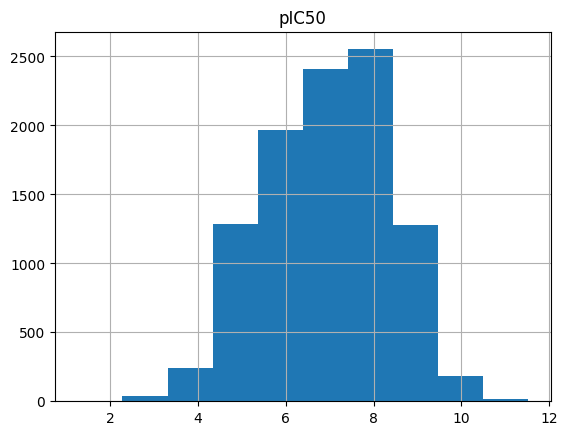

In [43]:
output_df.hist(column="pIC50")

接下来的步骤会在 `DataFrame` 中添加一列 RDKit 分子对象，并查看 pIC50 数值最高的分子结构。

In [44]:
# Add molecule column
PandasTools.AddMoleculeColumnToFrame(output_df, smilesCol="smiles")

In [45]:
# Sort molecules by pIC50
output_df.sort_values(by="pIC50", ascending=False, inplace=True)

# Reset index
output_df.reset_index(drop=True, inplace=True)

显示活性最高的三个分子，即 pIC50 数值最高的分子。

In [46]:
output_df.drop("smiles", axis=1).head(3)

,molecule_chembl_id,IC50,units,pIC50,ROMol
0,CHEMBL63786,0.003,nM,11.522879,<rdkit.Chem.rdchem.Mol object at 0x1190015b0>
1,CHEMBL53711,0.006,nM,11.221849,<rdkit.Chem.rdchem.Mol object at 0x118f74d60>
2,CHEMBL35820,0.006,nM,11.221849,<rdkit.Chem.rdchem.Mol object at 0x118f63e60>


In [47]:
# Prepare saving the dataset: Drop the ROMol column
output_df = output_df.drop("ROMol", axis=1)
print(f"DataFrame shape: {output_df.shape}")

DataFrame shape: (9979, 5)


#### 将输出数据固定到 ChEMBL 27 版本

这是一个技术性步骤。通常，我们会继续使用刚刚生成的最新数据集。

不过，在 TeachOpenCADD 平台中，我们倾向于将数据集固定到特定的 ChEMBL 版本（即 [ChEMBL 27](http://doi.org/10.6019/CHEMBL.database.27
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        
        )），这样本教程以及 CADD 流程中后续的教程就不会随数据库更新而改变，便于维护。


<div class="alert alert-block alert-info">

<b>注意：</b>如果你希望使用最新数据运行本笔记本，或希望研究其他靶点，请注释掉下面的单元格。

</div>


In [48]:
# Disable this cell to unfreeze the dataset
output_df = pd.read_csv(
    DATA / "EGFR_compounds_ea055ef.csv", index_col=0, float_precision="round_trip"
)
output_df.head()

,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL63786,0.003,nM,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,11.522879
1,CHEMBL35820,0.006,nM,CCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCC,11.221849
2,CHEMBL53711,0.006,nM,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.221849
3,CHEMBL66031,0.008,nM,Brc1cccc(Nc2ncnc3cc4[nH]cnc4cc23)c1,11.096910
4,CHEMBL53753,0.008,nM,CNc1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.096910


In [49]:
print(f"DataFrame shape: {output_df.shape}")
# NBVAL_CHECK_OUTPUT

DataFrame shape: (5568, 5)


#### 将输出数据写入文件

后续教程将使用这个生物活性与化合物数据集，因此我们将数据保存为 `csv` 文件。
保存时建议删除分子对象列，因为该列仅包含分子图像。


In [50]:
output_df.to_csv(DATA / "EGFR_compounds.csv")
output_df.head()

,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL63786,0.003,nM,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,11.522879
1,CHEMBL35820,0.006,nM,CCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCC,11.221849
2,CHEMBL53711,0.006,nM,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.221849
3,CHEMBL66031,0.008,nM,Brc1cccc(Nc2ncnc3cc4[nH]cnc4cc23)c1,11.096910
4,CHEMBL53753,0.008,nM,CNc1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.096910


In [51]:
print(f"DataFrame shape: {output_df.shape}")
# NBVAL_CHECK_OUTPUT

DataFrame shape: (5568, 5)


## 讨论

在本教程中，我们从 ChEMBL 数据库中收集了目标靶点的生物活性数据，并筛选出具有实测 IC50 生物活性值的分子。

请注意，ChEMBL 数据来自多种来源。不同实验室、不同研究者在世界各地生成了化合物数据。因此，基于这些数据集进行预测时需要谨慎。解释结果并判断预测可信度时，应充分考虑数据来源，以及不同测定实验在数据生成上的一致性。

在接下来的教程中，我们将根据 Lipinski 五规则和不希望出现的子结构进一步筛选所获数据。分子数据清洗也是重要步骤。由于目前的教程尚未介绍这部分内容，我们推荐使用 [Standardiser 库](https://github.com/flatkinson/standardiser)或 [MolVS](https://molvs.readthedocs.io/en/latest/) 等工具。


## 测验

* 本教程从 ChEMBL 下载了分子及其生物活性数据。ChEMBL 数据库还可用于哪些研究？
* IC50 和 EC50 有何区别？
* 从 ChEMBL 提取的数据可用于哪些任务？


## 面向 CADD 博士生的延伸练习

本教程在生物活性数据预处理中，对每个化合物只保留第一条 IC50 记录。请在去重前保留测定信息，设计一个更稳健的化合物活性汇总与排序方案：

1. 将 nM 单位的 IC50 转为 pIC50，并对每个化合物汇总多次测定（例如报告中位数、测定次数和离散程度）。
2. 按 `assay_chembl_id` 或测定描述分层，比较不同实验间的活性差异及化合物排序的一致性。
3. 说明测定条件和数据来源的异质性如何影响活性标签、虚拟筛选排序与模型训练；列出你会在报告中保留的质量控制信息。

讨论时请区分实验测得的 IC50 与靶点结合亲和力或体内药效，不要将它们直接等同。

## 中文版本与来源说明

本文件为 TeachOpenCADD T001 的中文译本，并补充了上述练习。示例代码和已保存的输出与上游英文教程一致。原作者信息保留在笔记本开头。上游来源：[TeachOpenCADD T001（commit `834b9ff59af69e8ba8d42aae23e92c15eb734ef0`）](https://github.com/volkamerlab/teachopencadd/blob/834b9ff59af69e8ba8d42aae23e92c15eb734ef0/teachopencadd/talktorials/T001_query_chembl/talktorial.ipynb)。上游项目采用 [Creative Commons Attribution 4.0 International（CC BY 4.0）](https://creativecommons.org/licenses/by/4.0/) 许可；图 2 等第三方素材仍按原图注所列许可。